# Association Rules Analysis

## Business Goals

Discover hidden patterns and relationships between job characteristics (salary, experience, education, AI exposure, skills) and automation risk levels through association rule mining. This analysis aims to:

- Identify which combinations of features frequently lead to high/medium/low automation risk
- Uncover non-obvious relationships between job attributes
- Provide actionable insights for workforce planning and career development strategies
- Support decision-making by revealing co-occurrence patterns in the data


## Selected Algorithm

Unlike classification models that predict individual outcomes, association rules reveal:

- Co-occurrence patterns: "Jobs with X characteristic tend to also have Y characteristic"
- Implication relationships: "IF condition A, THEN outcome B (with confidence %)"
- Market basket insights: Similar to retail analysis, but for job attributes

# Key Metrics

Support: How frequently an itemset appears in the dataset

- Formula: support(A) = count(A) / total_transactions
- Interpretation: Measures prevalence/popularity

Confidence: Probability that consequent occurs given antecedent

- Formula: confidence(A → B) = support(A ∪ B) / support(A)
- Interpretation: Measures rule reliability

Lift: Strength of association compared to random chance

- Formula: lift(A → B) = confidence(A → B) / support(B)
- Interpretation:

  - Lift > 1: Positive correlation
  - Lift = 1: No correlation
  - Lift < 1: Negative correlation

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Association Rules
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Configuration
import warnings
warnings.filterwarnings('ignore')

# Visualization settings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

print("=" * 80)
print("ASSOCIATION RULES ANALYSIS - NOTEBOOK 3")
print("=" * 80)

# Load dataset
df = pd.read_csv('AI_Impact_on_Jobs_2030.csv')

print("\n" + "=" * 80)
print("STEP 1: DATA EXPLORATION")
print("=" * 80)
print(f"\nDataset shape: {df.shape}")
print(f"\nFirst rows:")
print(df.head())

ASSOCIATION RULES ANALYSIS - NOTEBOOK 3

STEP 1: DATA EXPLORATION

Dataset shape: (3000, 18)

First rows:
             Job_Title  Average_Salary  Years_Experience Education_Level  \
0       Security Guard           45795                28        Master's   
1   Research Scientist          133355                20             PhD   
2  Construction Worker          146216                 2     High School   
3    Software Engineer          136530                13             PhD   
4    Financial Analyst           70397                22     High School   

   AI_Exposure_Index  Tech_Growth_Factor  Automation_Probability_2030  \
0               0.18                1.28                         0.85   
1               0.62                1.11                         0.05   
2               0.86                1.18                         0.81   
3               0.39                0.68                         0.60   
4               0.52                1.46                         0.64   

In [4]:
print("\n" + "=" * 80)
print("STEP 2: DATA PREPARATION FOR ASSOCIATION RULES")
print("=" * 80)

# Create a copy for transformation
df_rules = df.copy()

# 1. Discretize continuous variables into meaningful categories
print("\nDiscretizing continuous variables...")

# Salary ranges
df_rules['Salary_Range'] = pd.qcut(df_rules['Average_Salary'], 
                                   q=4,
                                   labels=['Low_Salary', 'Medium_Salary', 'High_Salary', 'Very_High_Salary'])

# Experience levels
df_rules['Experience_Level'] = pd.qcut(df_rules['Years_Experience'],
                                       q=4,
                                      labels=['Entry_Level', 'Mid_Level', 'Senior_Level', 'Expert_Level'])

# AI Exposure categories
df_rules['AI_Exposure_Cat'] = pd.qcut(df_rules['AI_Exposure_Index'],
                                     q=3,
                                     labels=['Low_AI_Exposure', 'Medium_AI_Exposure', 'High_AI_Exposure'])

# Tech Growth categories
df_rules['Tech_Growth_Cat'] = pd.qcut(df_rules['Tech_Growth_Factor'],
                                     q=3,
                                     labels=['Slow_Tech_Growth', 'Medium_Tech_Growth', 'Fast_Tech_Growth'])

# Automation Probability categories
df_rules['Automation_Prob_Cat'] = pd.qcut(df_rules['Automation_Probability_2030'],
                                         q=3,
                                         labels=['Low_Automation_Prob', 'Medium_Automation_Prob', 'High_Automation_Prob'])

print("Continuous variables discretized")

# 2. Discretize skills into High/Low based on median
print("\nDiscretizing skill levels...")
skill_cols = [f'Skill_{i}' for i in range(1, 11)]

for skill in skill_cols:
    median_val = df_rules[skill].median()
    df_rules[f'{skill}_Level'] = df_rules[skill].apply(
        lambda x: f'High_{skill}' if x >= median_val else f'Low_{skill}'
    )

print("Skills discretized into High/Low levels")

# 3. Rename Education and Risk for clarity
df_rules['Education'] = 'Edu_' + df_rules['Education_Level'].astype(str)
df_rules['Risk'] = 'Risk_' + df_rules['Risk_Category'].astype(str)

print("\n" + "-" * 80)
print("Transformed Features Summary:")
print("-" * 80)
print(f"\nSalary Range distribution:")
print(df_rules['Salary_Range'].value_counts())
print(f"\nExperience Level distribution:")
print(df_rules['Experience_Level'].value_counts())
print(f"\nAI Exposure Category distribution:")
print(df_rules['AI_Exposure_Cat'].value_counts())
print(f"\nRisk Category distribution:")
print(df_rules['Risk'].value_counts())


STEP 2: DATA PREPARATION FOR ASSOCIATION RULES

Discretizing continuous variables...
Continuous variables discretized

Discretizing skill levels...
Skills discretized into High/Low levels

--------------------------------------------------------------------------------
Transformed Features Summary:
--------------------------------------------------------------------------------

Salary Range distribution:
Salary_Range
Low_Salary          750
Medium_Salary       750
High_Salary         750
Very_High_Salary    750
Name: count, dtype: int64

Experience Level distribution:
Experience_Level
Mid_Level       791
Entry_Level     787
Expert_Level    722
Senior_Level    700
Name: count, dtype: int64

AI Exposure Category distribution:
AI_Exposure_Cat
Medium_AI_Exposure    1016
Low_AI_Exposure       1008
High_AI_Exposure       976
Name: count, dtype: int64

Risk Category distribution:
Risk
Risk_Medium    1521
Risk_High       740
Risk_Low        739
Name: count, dtype: int64


In [5]:
print("\n" + "=" * 80)
print("STEP 3: CREATING TRANSACTION FORMAT")
print("=" * 80)

# Select relevant columns for association rules
categorical_cols = ['Salary_Range', 'Experience_Level', 'Education', 
                   'AI_Exposure_Cat', 'Tech_Growth_Cat', 'Automation_Prob_Cat', 'Risk']

# Add skill levels
skill_level_cols = [f'Skill_{i}_Level' for i in range(1, 11)]
categorical_cols.extend(skill_level_cols)

# Create transactions: each row becomes a list of items
transactions = []
for idx, row in df_rules.iterrows():
    transaction = []
    for col in categorical_cols:
        if pd.notna(row[col]):
            transaction.append(str(row[col]))
    transactions.append(transaction)

print(f"\nTotal transactions created: {len(transactions)}")
print(f"\nExample transaction (first job):")
print(transactions[0])

# Convert to one-hot encoded DataFrame
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

cols_to_exclude = []

#Excluding skill collumns ()
skill_cols_to_exclude = [f'Low_Skill_{i}' for i in range(1, 16)] + [f'High_Skill_{i}' for i in range(1, 16)]
cols_to_exclude.extend(skill_cols_to_exclude)

df_filtered = df_encoded.drop(columns=cols_to_exclude, errors='ignore')

print(f"\nEncoded dataset shape: {df_filtered.shape}")
print(f"Number of unique items: {len(te.columns_)}")

print("\n" + "=" * 80)
print("DATA PREPARATION COMPLETED!")
print("=" * 80)
print("\nDataset ready for Apriori algorithm")
print(f"{len(transactions)} transactions")
print(f"{len(te.columns_)} unique items")
print(f"Ready to mine association rules")


STEP 3: CREATING TRANSACTION FORMAT

Total transactions created: 3000

Example transaction (first job):
['Low_Salary', 'Expert_Level', "Edu_Master's", 'Low_AI_Exposure', 'Fast_Tech_Growth', 'High_Automation_Prob', 'Risk_High', 'Low_Skill_1', 'Low_Skill_2', 'Low_Skill_3', 'Low_Skill_4', 'Low_Skill_5', 'High_Skill_6', 'Low_Skill_7', 'High_Skill_8', 'High_Skill_9', 'Low_Skill_10']

Encoded dataset shape: (3000, 24)
Number of unique items: 44

DATA PREPARATION COMPLETED!

Dataset ready for Apriori algorithm
3000 transactions
44 unique items
Ready to mine association rules


In [6]:
print("\n" + "=" * 80)
print("STEP 4: APPLYING APRIORI ALGORITHM")
print("=" * 80)

# Start with a moderate support threshold
min_support = 0.04  # 2% of transactions
print(f"\nMining frequent itemsets with min_support = {min_support}")

frequent_itemsets = apriori(df_filtered, min_support=min_support, use_colnames=True)
print(f"Found {len(frequent_itemsets)} frequent itemsets")

if len(frequent_itemsets) > 0:
    print("\nTop 10 most frequent itemsets:")
    print(frequent_itemsets.nlargest(10, 'support')[['support', 'itemsets']])
else:
    print("\n⚠ No frequent itemsets found with this support threshold")

# Generate association rules
print("\n" + "-" * 80)
print("Generating Association Rules")
print("-" * 80)

if len(frequent_itemsets) > 0:
    # Generate rules with minimum confidence threshold
    min_confidence = 0.6
    print(f"Min confidence threshold: {min_confidence}")
    
    rules = association_rules(frequent_itemsets, 
                             metric="confidence", 
                             min_threshold=min_confidence)
    
    print(f"\nGenerated {len(rules)} association rules")
    


STEP 4: APPLYING APRIORI ALGORITHM

Mining frequent itemsets with min_support = 0.04
Found 388 frequent itemsets

Top 10 most frequent itemsets:
      support                               itemsets
20   0.507000                          (Risk_Medium)
16   0.344333                   (Medium_Tech_Growth)
13   0.338667                   (Medium_AI_Exposure)
10   0.336000                      (Low_AI_Exposure)
11   0.335333                  (Low_Automation_Prob)
22   0.334333                     (Slow_Tech_Growth)
8    0.332667                 (High_Automation_Prob)
14   0.332000               (Medium_Automation_Prob)
232  0.332000  (Risk_Medium, Medium_Automation_Prob)
7    0.325333                     (High_AI_Exposure)

--------------------------------------------------------------------------------
Generating Association Rules
--------------------------------------------------------------------------------
Min confidence threshold: 0.6

Generated 116 association rules



STEP 5: RULE ANALYSIS AND EVALUATION

--------------------------------------------------------------------------------
TOP 15 RULES BY CONFIDENCE
--------------------------------------------------------------------------------

Rule 1:
  IF ['Risk_High']
  THEN ['High_Automation_Prob']
  Support: 0.247, Confidence: 1.000, Lift: 3.006

Rule 2:
  IF ['Risk_Low']
  THEN ['Low_Automation_Prob']
  Support: 0.246, Confidence: 1.000, Lift: 2.982

Rule 3:
  IF ['Medium_Automation_Prob']
  THEN ['Risk_Medium']
  Support: 0.332, Confidence: 1.000, Lift: 1.972

Rule 4:
  IF ["Edu_Bachelor's", 'Risk_High']
  THEN ['High_Automation_Prob']
  Support: 0.063, Confidence: 1.000, Lift: 3.006

Rule 5:
  IF ['Risk_Low', "Edu_Bachelor's"]
  THEN ['Low_Automation_Prob']
  Support: 0.063, Confidence: 1.000, Lift: 2.982

Rule 6:
  IF ["Edu_Bachelor's", 'Medium_Automation_Prob']
  THEN ['Risk_Medium']
  Support: 0.081, Confidence: 1.000, Lift: 1.972

Rule 7:
  IF ['Edu_High School', 'Risk_High']
  THEN ['High

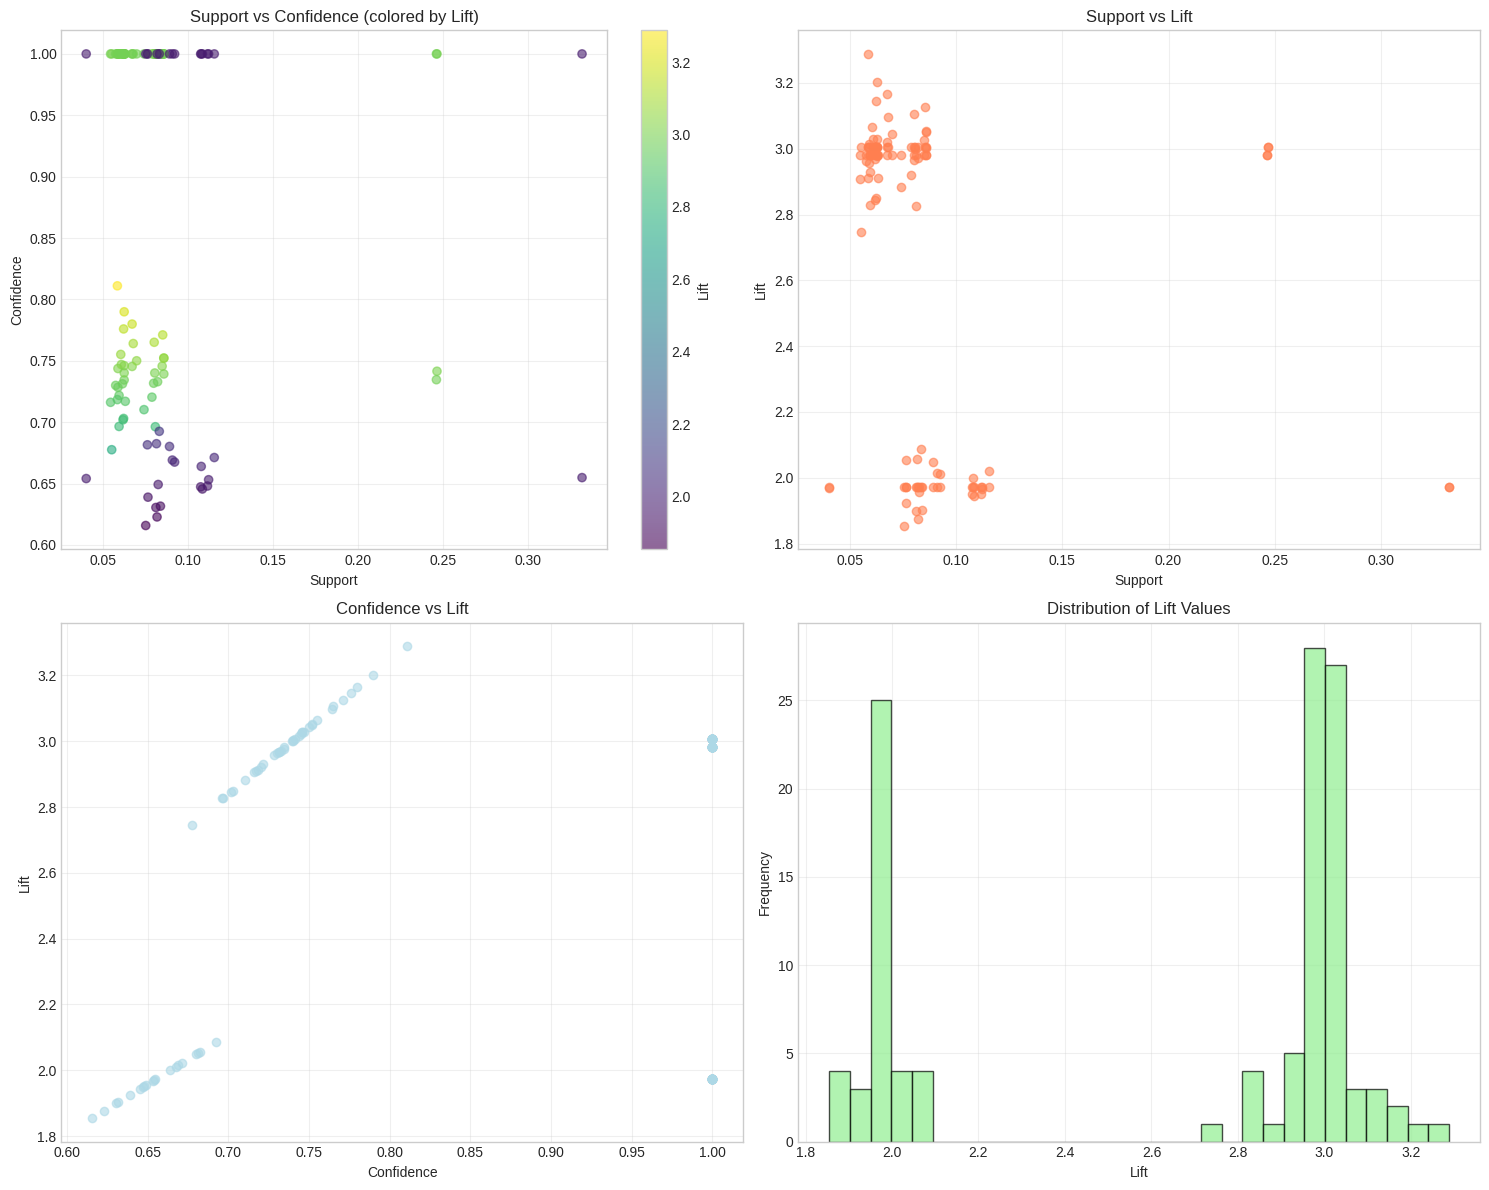


Visualizations created successfully


In [7]:
if len(rules) > 0:
    # Calculate additional metrics
    rules['leverage'] = rules['support'] - (rules['antecedent support'] * rules['consequent support'])
    rules['conviction'] = np.where(
        rules['confidence'] == 1.0,
        np.inf,
        (1 - rules['consequent support']) / (1 - rules['confidence'])
    )

    print("\n" + "=" * 80)
    print("STEP 5: RULE ANALYSIS AND EVALUATION")
    print("=" * 80)

    # TOP 15 BY CONFIDENCE
    print("\n" + "-" * 80)
    print("TOP 15 RULES BY CONFIDENCE")
    print("-" * 80)
    top_confidence = rules.nlargest(15, 'confidence')[
        ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    ].reset_index(drop=True)
    for i, row in top_confidence.iterrows():
        print(f"\nRule {i + 1}:")
        print(f"  IF {list(row['antecedents'])}")
        print(f"  THEN {list(row['consequents'])}")
        print(f"  Support: {row['support']:.3f}, Confidence: {row['confidence']:.3f}, Lift: {row['lift']:.3f}")

    # TOP 15 BY LIFT (fora do loop anterior)
    print("\n" + "-" * 80)
    print("TOP 15 RULES BY LIFT")
    print("-" * 80)
    top_lift = rules.nlargest(15, 'lift')[
        ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    ].reset_index(drop=True)
    for i, row in top_lift.iterrows():
        print(f"\nRule {i + 1}:")
        print(f"  IF {list(row['antecedents'])}")
        print(f"  THEN {list(row['consequents'])}")
        print(f"  Support: {row['support']:.3f}, Confidence: {row['confidence']:.3f}, Lift: {row['lift']:.3f}")

    # Filter rules related to Risk Categories
    print("\n" + "-" * 80)
    print("RULES PREDICTING AUTOMATION RISK")
    print("-" * 80)

    risk_rules = rules[
        rules['consequents'].apply(lambda x: any('Risk_' in str(item) for item in x))
    ].sort_values('confidence', ascending=False).reset_index(drop=True)

    if len(risk_rules) > 0:
        print(f"\nFound {len(risk_rules)} rules predicting risk categories")
        print("\nTop 10 Risk Prediction Rules:")
        for i, row in risk_rules.head(10).iterrows():
            print(f"\nRule {i + 1}:")
            print(f"  IF {list(row['antecedents'])}")
            print(f"  THEN {list(row['consequents'])}")
            print(f"  Support: {row['support']:.3f}, Confidence: {row['confidence']:.3f}, Lift: {row['lift']:.3f}")
    else:
        print("\n No rules found predicting risk categories")
        
    # Visualizations
    print("\n" + "=" * 80)
    print("STEP 6: VISUALIZATIONS")
    print("=" * 80)
        
    # 1. Support vs Confidence scatter plot
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        
    # Support vs Confidence
    axes[0, 0].scatter(rules['support'], rules['confidence'], 
                      c=rules['lift'], cmap='viridis', alpha=0.6)
    axes[0, 0].set_xlabel('Support')
    axes[0, 0].set_ylabel('Confidence')
    axes[0, 0].set_title('Support vs Confidence (colored by Lift)')
    axes[0, 0].grid(True, alpha=0.3)
    cbar1 = plt.colorbar(axes[0, 0].collections[0], ax=axes[0, 0])
    cbar1.set_label('Lift')
        
    # Support vs Lift
    axes[0, 1].scatter(rules['support'], rules['lift'], alpha=0.6, color='coral')
    axes[0, 1].set_xlabel('Support')
    axes[0, 1].set_ylabel('Lift')
    axes[0, 1].set_title('Support vs Lift')
    axes[0, 1].grid(True, alpha=0.3)
        
    # Confidence vs Lift
    axes[1, 0].scatter(rules['confidence'], rules['lift'], alpha=0.6, color='lightblue')
    axes[1, 0].set_xlabel('Confidence')
    axes[1, 0].set_ylabel('Lift')
    axes[1, 0].set_title('Confidence vs Lift')
    axes[1, 0].grid(True, alpha=0.3)
        
    # Distribution of lift values
    axes[1, 1].hist(rules['lift'], bins=30, edgecolor='black', alpha=0.7, color='lightgreen')
    axes[1, 1].set_xlabel('Lift')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Distribution of Lift Values')
    axes[1, 1].grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()
        
    print("\nVisualizations created successfully")
else:
    print("\nCannot generate rules without frequent itemsets")


STEP 7: PARAMETER OPTIMIZATION

Testing different parameter combinations...
--------------------------------------------------------------------------------
Support: 0.04, Confidence: 0.30 → 388 itemsets, 520 rules, Avg Lift: 1.43
Support: 0.04, Confidence: 0.50 → 388 itemsets, 173 rules, Avg Lift: 2.11
Support: 0.04, Confidence: 0.70 → 388 itemsets, 93 rules, Avg Lift: 2.78
Support: 0.04, Confidence: 0.90 → 388 itemsets, 58 rules, Avg Lift: 2.64
Support: 0.06, Confidence: 0.30 → 288 itemsets, 350 rules, Avg Lift: 1.52
Support: 0.06, Confidence: 0.50 → 288 itemsets, 110 rules, Avg Lift: 2.39
Support: 0.06, Confidence: 0.70 → 288 itemsets, 76 rules, Avg Lift: 2.75
Support: 0.06, Confidence: 0.90 → 288 itemsets, 48 rules, Avg Lift: 2.59
Support: 0.08, Confidence: 0.30 → 193 itemsets, 275 rules, Avg Lift: 1.39
Support: 0.08, Confidence: 0.50 → 193 itemsets, 69 rules, Avg Lift: 2.15
Support: 0.08, Confidence: 0.70 → 193 itemsets, 39 rules, Avg Lift: 2.58
Support: 0.08, Confidence: 0.90 → 

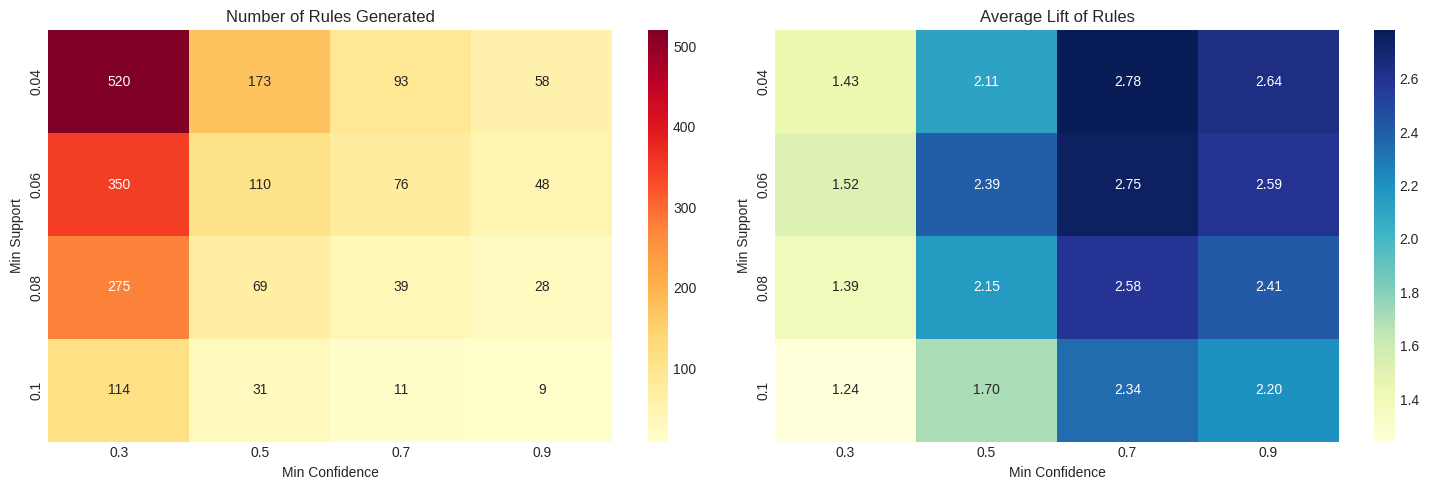


✓ Parameter optimization completed


In [8]:
# ============================================================================
# STEP 7: PARAMETER OPTIMIZATION
# ============================================================================

print("\n" + "=" * 80)
print("STEP 7: PARAMETER OPTIMIZATION")
print("=" * 80)

# Test different support and confidence thresholds
support_thresholds = [0.04, 0.06, 0.08, 0.10]
confidence_thresholds = [0.3, 0.5, 0.7, 0.9]

optimization_results = []

print("\nTesting different parameter combinations...")
print("-" * 80)

for sup in support_thresholds:
    freq_items = apriori(df_filtered, min_support=sup, use_colnames=True)
    
    for conf in confidence_thresholds:
        if len(freq_items) > 0:
            rules_test = association_rules(freq_items, 
                                          metric="confidence", 
                                          min_threshold=conf)
            
            if len(rules_test) > 0:
                avg_lift = rules_test['lift'].mean()
                avg_confidence = rules_test['confidence'].mean()
                
                optimization_results.append({
                    'min_support': sup,
                    'min_confidence': conf,
                    'num_itemsets': len(freq_items),
                    'num_rules': len(rules_test),
                    'avg_lift': avg_lift,
                    'avg_confidence': avg_confidence
                })
                
                print(f"Support: {sup:.2f}, Confidence: {conf:.2f} → "
                      f"{len(freq_items)} itemsets, {len(rules_test)} rules, "
                      f"Avg Lift: {avg_lift:.2f}")

# Create summary DataFrame
if optimization_results:
    opt_df = pd.DataFrame(optimization_results)
    
    print("\n" + "-" * 80)
    print("OPTIMIZATION SUMMARY")
    print("-" * 80)
    print(opt_df.to_string(index=False))
    
    # Find best parameters (balance between number of rules and quality)
    opt_df['score'] = (opt_df['num_rules'] / opt_df['num_rules'].max()) * opt_df['avg_lift']
    best_params = opt_df.loc[opt_df['score'].idxmax()]
    
    print("\n" + "-" * 80)
    print("RECOMMENDED PARAMETERS")
    print("-" * 80)
    print(f"Min Support: {best_params['min_support']:.2f}")
    print(f"Min Confidence: {best_params['min_confidence']:.2f}")
    print(f"Expected Rules: {int(best_params['num_rules'])}")
    print(f"Average Lift: {best_params['avg_lift']:.2f}")
    
    # Visualize optimization results
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Number of rules vs parameters
    pivot_rules = opt_df.pivot(index='min_support', 
                               columns='min_confidence', 
                               values='num_rules')
    sns.heatmap(pivot_rules, annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[0])
    axes[0].set_title('Number of Rules Generated')
    axes[0].set_xlabel('Min Confidence')
    axes[0].set_ylabel('Min Support')
    
    # Average lift vs parameters
    pivot_lift = opt_df.pivot(index='min_support', 
                             columns='min_confidence', 
                             values='avg_lift')
    sns.heatmap(pivot_lift, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[1])
    axes[1].set_title('Average Lift of Rules')
    axes[1].set_xlabel('Min Confidence')
    axes[1].set_ylabel('Min Support')
    
    plt.tight_layout()
    plt.show()
    
    print("\n✓ Parameter optimization completed")

In [9]:
print("\n" + "=" * 80)
print("STEP 8: KEY INSIGHTS AND BUSINESS IMPLICATIONS")
print("=" * 80)

TOP_N = 3  

if 'rules' in locals() and len(rules) > 0:
    # Normalize index for consistent numbering
    rules = rules.reset_index(drop=True)

    # Helper to check membership in consequents 
    def consequent_contains(rule_consequents, target):
        return any(str(item) == target for item in rule_consequents)

    # Filter rules by risk categories and sort by confidence (desc)
    high_risk_rules = rules[
        rules['consequents'].apply(lambda x: consequent_contains(x, 'Risk_High'))
    ].sort_values('confidence', ascending=False).reset_index(drop=True)

    medium_risk_rules = rules[
        rules['consequents'].apply(lambda x: consequent_contains(x, 'Risk_Medium'))
    ].sort_values('confidence', ascending=False).reset_index(drop=True)


    low_risk_rules = rules[
        rules['consequents'].apply(lambda x: consequent_contains(x, 'Risk_Low'))
    ].sort_values('confidence', ascending=False).reset_index(drop=True)

    # Print summaries and top N examples
    print("\n" + "-" * 80)
    print("AUTOMATION RISK PATTERNS")
    print("-" * 80)

    print(f"\nHigh Risk Patterns: {len(high_risk_rules)} rules found")
    if len(high_risk_rules) > 0:
        print(f"\nTop {TOP_N} High Risk Indicators:")
        for i, row in high_risk_rules.head(TOP_N).iterrows():
            antecedents = sorted(list(row['antecedents']))
            consequents = sorted(list(row['consequents']))
            print(f"\n  Rule {i + 1}:")
            print(f"    • IF {antecedents}")
            print(f"    • THEN {consequents}")
            print(f"    • Support: {row['support']:.3f}, Confidence: {row['confidence']:.2%}, Lift: {row['lift']:.3f}")

    print(f"\nMedium Risk Patterns: {len(medium_risk_rules)} rules found")
    if len(medium_risk_rules) > 0:
        print(f"\nTop {TOP_N} Medium Risk Indicators:")
        for i, row in medium_risk_rules.head(TOP_N).iterrows():
            antecedents = sorted(list(row['antecedents']))
            consequents = sorted(list(row['consequents']))
            print(f"\n  Rule {i + 1}:")
            print(f"    • IF {antecedents}")
            print(f"    • THEN {consequents}")
            print(f"    • Support: {row['support']:.3f}, Confidence: {row['confidence']:.2%}, Lift: {row['lift']:.3f}")

    print(f"\nLow Risk Patterns: {len(low_risk_rules)} rules found")
    if len(low_risk_rules) > 0:
        print(f"\nTop {TOP_N} Low Risk Indicators:")
        for i, row in low_risk_rules.head(TOP_N).iterrows():
            antecedents = sorted(list(row['antecedents']))
            consequents = sorted(list(row['consequents']))
            print(f"\n  Rule {i + 1}:")
            print(f"    • IF {antecedents}")
            print(f"    • THEN {consequents}")
            print(f"    • Support: {row['support']:.3f}, Confidence: {row['confidence']:.2%}, Lift: {row['lift']:.3f}")
else:
    print("\nNo rules available to analyze")



STEP 8: KEY INSIGHTS AND BUSINESS IMPLICATIONS

--------------------------------------------------------------------------------
AUTOMATION RISK PATTERNS
--------------------------------------------------------------------------------

High Risk Patterns: 19 rules found

Top 3 High Risk Indicators:

  Rule 1:
    • IF ['High_Automation_Prob', 'Senior_Level']
    • THEN ['Risk_High']
    • Support: 0.059, Confidence: 81.11%, Lift: 3.288

  Rule 2:
    • IF ["Edu_Master's", 'High_Automation_Prob']
    • THEN ['Risk_High']
    • Support: 0.063, Confidence: 78.99%, Lift: 3.202

  Rule 3:
    • IF ['High_Automation_Prob', 'Medium_Salary']
    • THEN ['Risk_High']
    • Support: 0.062, Confidence: 77.59%, Lift: 3.146

Medium Risk Patterns: 20 rules found

Top 3 Medium Risk Indicators:

  Rule 1:
    • IF ['Medium_Automation_Prob']
    • THEN ['Risk_Medium']
    • Support: 0.332, Confidence: 100.00%, Lift: 1.972

  Rule 2:
    • IF ["Edu_Bachelor's", 'Medium_Automation_Prob']
    • THEN ['Ri